# <font color=#138D75> **Introduction to Jupyter**</font> 

## <font color=#138D75> Cell types</font> 

A Jupyter notebook consists of a number of different cells which can be executed in any order. Cells can be of three types, but the two types important for us are:
- **Markdown** $-$ where you write text and equations, can add hyperlinks, figures, and more.
- **Code** $-$ which contain executable (Python) code.

The cell-type is selected in a scroll-down list at the top of the notebook window. A cell is executed by selecting the cell and pressing `shift`+`enter`, or the `run` button (&#9654;) at the top. 
- For markdown cells, this formats the text.
- For code cells, it runs the code.

The results of running code cells are saved in memory. It is often a good idea to separate your code into several blocks.

### <font color=#138D75> Markdown cells </font>

[Markdown](https://www.markdownguide.org/) is a lightweight language for creating formatted text, including equations which can be written in a syntax very similar to Latex, for example:

$$
\mathbf{F} = m\, \mathbf{a}.
$$

To modify a **markdown** cell, simply double click on it.
Besides text and equations, it's also possible to add images by dragging and dropping the image file to the **markdown** cell in edit mode. More information about the basic syntax of markdown can be found [here](https://www.markdownguide.org/basic-syntax).

### <font color=#138D75> Code cells </font>

Code cells are executable blocks of Python code. For example, we can define a routine and use it subsequently:

In [3]:
def sum_numbers(a, b):
    return a + b

In [4]:
sum_numbers(1, 2.0)

3.0

### <font color=#138D75> The Python ecosystem </font> 

Python has a large number of modules and packages available, the main ones which we will use in this notebook are:

- `numpy`: large collection of mathematical functionalities
- `matplotlib`: library for plotting
- `scipy`: library for scientific and technical computing
- `h5py`: library for writting and reading binary checkpoint files.

These modules can be loaded as a whole (often given an alias to avoid function collisions and overwriting), or by loading specific submodules.

In [5]:
import numpy as np
import scipy
import h5py
from matplotlib import pyplot as plt

In [6]:
import sys; print(sys.executable)

C:\Users\raulu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


Functionalities from the packages are used by calling the appropriate package and routine. You can directly access the documentation for any package, class, or routine, by running `help` on the object/routine you are interested in. For example: 

In [7]:
help(plt.plot)

Help on function plot in module matplotlib.pyplot:

plot(
    *args: 'float | ArrayLike | str',
    scalex: 'bool' = True,
    scaley: 'bool' = True,
    data=None,
    **kwargs
) -> 'list[Line2D]'
    Plot y versus x as lines and/or markers.

    Call signatures::

        plot([x], y, [fmt], *, data=None, **kwargs)
        plot([x], y, [fmt], [x2], y2, [fmt2], ..., **kwargs)

    The coordinates of the points or line nodes are given by *x*, *y*.

    The optional parameter *fmt* is a convenient way for defining basic
    formatting like color, marker and linestyle. It's a shortcut string
    notation described in the *Notes* section below.

    >>> plot(x, y)        # plot x and y using default line style and color
    >>> plot(x, y, 'bo')  # plot x and y using blue circle markers
    >>> plot(y)           # plot y using x as index array 0..N-1
    >>> plot(y, 'r+')     # ditto, but with red plusses

    You can use `.Line2D` properties as keyword arguments for more
    control on th

## <font color=#138D75> Exercises</font>

Fill in the missing code blocks to solve the following exercises.

### <font color=#138D75> 1. The Morse potential</font>

Consider the one dimensional Morse potential

$$ V(x) = D_e\left[1 - e^{-a(x-x_0)}\right]^2 $$

which models the potential energy curve of a diatomic molecule, where $x_0$ is the equilibrium distance, $D_e$ the asymptotic limit and $a$ measures of the width of the potential well.

For given values of $D_e$, $x_0$, and $a$, implement a function in Python to calculate the Morse potential for a set of values of x defined by a Numpy array. Plot the result.

In [8]:
D_e = 5.0
x_0 = 1.2
a = 0.75

def V(D_e, x_0, a, x):
    return D_e * (1 - np.exp(-a * (x - x_0)))**2

Use `np.linspace` or `np.arange` to create an array of x values.

In [9]:
x = np.linspace(0, 10, 100)
y = V(D_e, x_0, a, x)

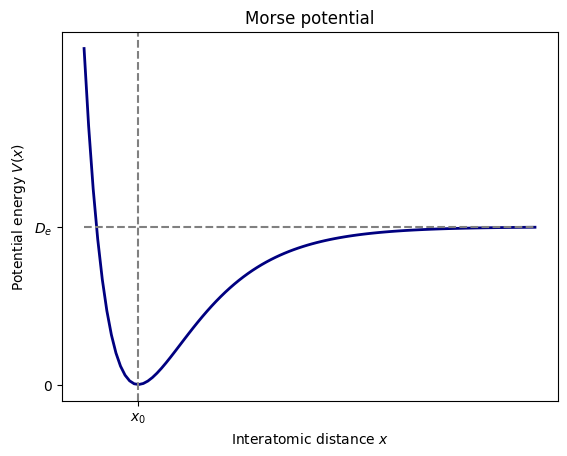

In [10]:
# Plot the Morse potential
x_min = np.min(x)
x_max = np.max(x)

plt.plot(x, y, color="navy", linewidth=2.0)
plt.hlines(D_e, x_min, x_max, linestyles="dashed", color="gray")
plt.axvline(x_0, ls="--", color="gray")
plt.xticks([x_0], ['$x_0$'])
plt.yticks([0, D_e], ['0', '$D_e$'])
plt.title('Morse potential')
plt.xlabel('Interatomic distance $x$')
plt.ylabel('Potential energy $V(x)$')
plt.show()

**Q1**. How do the parameters $D_e$, $a$, and $x_0$ affect the potential shape?

### <font color=#138D75> 2. The gradient of the Morse potential</font>
Implement a routine which calculates and plots the gradient of the Morse potential. You can either calculate the gradient analytically or numerically.

In [11]:
def grad_V(x,y):
    return np.gradient(y, x)

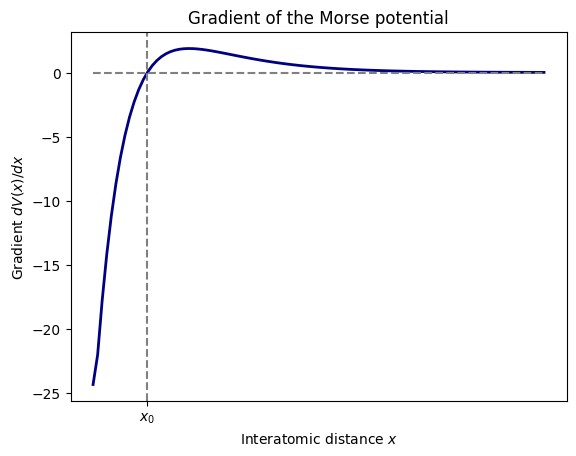

In [12]:
# Plot the function
x_min = np.min(x)
x_max = np.max(x)

plt.plot(x, grad_V(x, y), color="navy", linewidth=2.0)
plt.hlines(0, x_min, x_max, linestyles="dashed", color="gray")
plt.axvline(x_0, ls="--", color="gray")
plt.xticks([x_0], ['$x_0$'])
plt.title('Gradient of the Morse potential')
plt.xlabel('Interatomic distance $x$')
plt.ylabel('Gradient $dV(x)/dx$')
plt.show()

**Q2**. How can you determine that your gradient has been implemented correctly? 

First of all, the gradient can be checked visually by comparing its plot with the plot of the Morse potential:

- At the minimum of the potential ($x = x_0$) the gradient must be zero.
- Before the minimum ($x < x_0$) the potential decreases, so the gradient must be negative.
- After the minimum ($x > x_0$) the potential increases, so the gradient must be positive.
- For large $x$ the potential stops growing and flattens out at $D_e$, so the gradient must go back to zero.

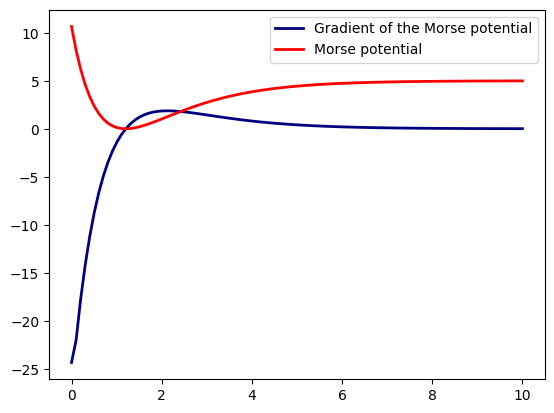

In [13]:
plt.plot(x, grad_V(x, y), color="navy", linewidth=2.0, label='Gradient of the Morse potential')
plt.plot(x, y, color="red", linewidth=2.0, label='Morse potential')
plt.legend(); plt.show()

### <font color=#138D75> 3. The MP2 energy correction </font>
For a closed-shell Hartree-Fock reference, the MP2 energy correction can be written as:

$$
E^{(2)} = E^{(2)}_\mathrm{os} + E^{(2)}_\mathrm{ss}
$$

where

$$
E^{(2)}_\mathrm{os}= - \sum_{i,j}\sum_{a, b}\frac{(ia|jb)(ia|jb)}{\epsilon_a + \epsilon_b - \epsilon_i - \epsilon_j}
$$

$$
E^{(2)}_\mathrm{ss} = - \sum_{i,j}\sum_{a, b}\frac{(ia|jb)}{\epsilon_a + \epsilon_b - \epsilon_i - \epsilon_j}[(ia|jb) - (ib|ja)]
$$

Here, $(ia|jb)$ are electron repulsion integrals in Chemist notation, $\epsilon_i$, $\epsilon_j$ are the orbital energy eigenvalues of occupied orbitals, while $\epsilon_a$, $\epsilon_b$ are orbital energy eigenvalues of virtual (unoccupied) orbitals.

The electron repulsion integrals calculated for the water molecule are stored as 4-dimensional Numpy arrays in the [water.h5](https://drive.google.com/file/d/1H_Xd4Sw1FqlKnvUD8SNogQaDeN6t3yfB/view?usp=sharing) checkpoint file and are labelled as "ovov". The occupied and virtual orbital energies are stored as 1D arrays labelled "e_occ", respectively "e_vir". Download the checkpoint file, read in the data and print the array shapes. 

In [14]:
# Open the file for reading
checkpoint_file = h5py.File("water.h5", "r")

ovov = np.array(checkpoint_file.get("ovov"))
e_occ = np.array(checkpoint_file.get("e_occ"))
e_vir = np.array(checkpoint_file.get("e_vir"))

# Close the checkpoint file
checkpoint_file.close()

In [15]:
print("Shape of ovov:", ovov.shape)
print("Shape of e_occ:", e_occ.shape)
print("Shape of e_vir:", e_vir.shape)

Shape of ovov: (5, 19, 5, 19)
Shape of e_occ: (5,)
Shape of e_vir: (19,)


Using Numpy routines or for-loops, calculate the following quantity

$$
\frac{(ia|jb)}{\epsilon_a + \epsilon_b - \epsilon_i - \epsilon_j}
$$    
and save it to the checkpoint file with label "ovov_div_eijab".

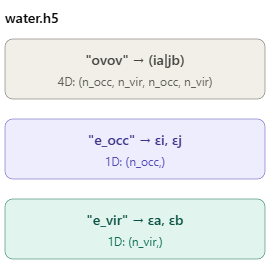

In [16]:
# Fill in your solution here
n_occ = len(e_occ)   # 5
n_vir = len(e_vir)   # 19

ovov_div_eijab = np.zeros_like(ovov)

for i in range(n_occ):          # 0 … 4
    for a in range(n_vir):      # 0 … 18
        for j in range(n_occ):  # 0 … 4
            for b in range(n_vir):  # 0 … 18
                den = e_vir[a] + e_vir[b] - e_occ[i] - e_occ[j]
                ovov_div_eijab[i, a, j, b] = ovov[i, a, j, b] / den

In [17]:
# To save to cehckpoint file, open it in append mode
checkpoint_file = h5py.File("water.h5", "a")

# Create the dataset with label ovov_div_eijab
checkpoint_file.create_dataset("ovov_div_eijab", data=ovov_div_eijab)

# Close the checkpoint file
checkpoint_file.close()

In [18]:
print(ovov.shape, ovov_div_eijab.shape)

(5, 19, 5, 19) (5, 19, 5, 19)


Using the `einsum` routine of Numpy, calculate the MP2 energy correction based on the `ovov_div_eijab` array and the equations: 

$$
E^{(2)} = E^{(2)}_\mathrm{os} + E^{(2)}_\mathrm{ss}
$$

where

$$
E^{(2)}_\mathrm{os}= - \sum_{i,j}\sum_{a, b}\frac{(ia|jb)(ia|jb)}{\epsilon_a + \epsilon_b - \epsilon_i - \epsilon_j}
$$

$$
E^{(2)}_\mathrm{ss} = - \sum_{i,j}\sum_{a, b}\frac{(ia|jb)}{\epsilon_a + \epsilon_b - \epsilon_i - \epsilon_j}[(ia|jb) - (ib|ja)]
$$

In [19]:
from numpy._core.einsumfunc import einsum
help(einsum)

Help on _ArrayFunctionDispatcher in module numpy:

einsum(*operands, out=None, optimize=False, **kwargs)
    einsum(subscripts, *operands, out=None, dtype=None, order='K',
           casting='safe', optimize=False)

    Evaluates the Einstein summation convention on the operands.

    Using the Einstein summation convention, many common multi-dimensional,
    linear algebraic array operations can be represented in a simple fashion.
    In *implicit* mode `einsum` computes these values.

    In *explicit* mode, `einsum` provides further flexibility to compute
    other array operations that might not be considered classical Einstein
    summation operations, by disabling, or forcing summation over specified
    subscript labels.

    See the notes and examples for clarification.

    Parameters
    ----------
    subscripts : str
        Specifies the subscripts for summation as comma separated list of
        subscript labels. An implicit (classical Einstein summation)
        calculat

E_os = − Σ (para todo i, a, j, b) ovov_div_eijab × (ia|jb)

E_ss = − Σ (para todo i, a, j, b) de ovov_div_eijab × [(ia|jb) − (ib|ja)] = − Σ (para todo i, a, j, b) de ovov_div_eijab × [(ia|jb)] + Σ (para todo i, a, j, b) de ovov_div_eijab × [(ib|ja)] = E_os + Σ (para todo i, a, j, b) de ovov_div_eijab × [(ib|ja)]


I think I did correctly the mathematics, if I understood correctly

In [38]:
e_os = - np.einsum("iajb,iajb->", ovov_div_eijab, ovov)
e_ss = e_os + np.einsum("iajb,ibja->", ovov_div_eijab, ovov)
e_mp2 = e_os + e_ss

Verify that your result is correct by comparing to the energy correction read from checkpoint:

In [39]:
checkpoint_file = h5py.File("water.h5", "r")
mp2_ref = np.array(checkpoint_file.get("mp2_energy"))[0]
checkpoint_file.close()

In [40]:
print("Reference MP2 energy correction: %.5f H." % mp2_ref)

Reference MP2 energy correction: -0.20577 H.


In [41]:
print("My MP2 correction: %.5f H." % e_mp2)

My MP2 correction: -0.20577 H.
